In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle (1).json


In [ ]:
import os
import json

# Create the Kaggle configuration directory
os.makedirs("/root/.kaggle", exist_ok=True)

# Read the uploaded kaggle.json file
with open("kaggle.json", "r") as f:
    creds = json.load(f)

# Standardize 'api_key' to 'key' if needed
if "api_key" in creds:
    creds["key"] = creds.pop("api_key")

# Write the corrected credentials back to the Kaggle folder
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(creds, f)

# Set secure file permissions
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured successfully with corrected keys!")

Kaggle API configured successfully with corrected keys!


In [ ]:
!kaggle datasets download -d krantiswalke/bank-personal-loan-modelling

Dataset URL: https://www.kaggle.com/datasets/krantiswalke/bank-personal-loan-modelling
License(s): unknown
100% 60.6k/60.6k [00:00<00:00, 72.8MB/s]



In [ ]:
!kaggle datasets download -d krantiswalke/bank-personal-loan-modelling

Dataset URL: https://www.kaggle.com/datasets/krantiswalke/bank-personal-loan-modelling
License(s): unknown
bank-personal-loan-modelling.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!kaggle datasets download -d krantiswalke/bank-personal-loan-modelling

Dataset URL: https://www.kaggle.com/datasets/krantiswalke/bank-personal-loan-modelling
License(s): unknown
bank-personal-loan-modelling.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'kaggle.json', 'bank-personal-loan-modelling.zip', 'kaggle (1).json', 'sample_data']


In [ ]:
import os
import glob
import zipfile

zip_files = glob.glob("/content/*.zip")

if zip_files:
    zip_path = zip_files[-1]
    extract_path = "/content/bank_personal_loan"

    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully!")
    print("Files available:", os.listdir(extract_path))
else:
    print("No ZIP file found. Run the Kaggle download cell first.")

Dataset extracted successfully!
Files available: ['Bank_Personal_Loan_Modelling.csv']


In [ ]:
import pandas as pd
import glob
import os

files = (
    glob.glob("/content/bank_personal_loan/**/*.csv", recursive=True)
    + glob.glob("/content/bank_personal_loan/**/*.xlsx", recursive=True)
)

print("Available files:", files)

if not files:
    print("No files found! Please fix the Kaggle credential issue, re-download the dataset, and extract it.")
else:
    df = None
    for file in files:
        if file.endswith(".csv"):
            df = pd.read_csv(file)
            break
        elif file.endswith(".xlsx"):
            df = pd.read_excel(file)
            break

    if df is not None:
        display(df.head())
        print("Dataset shape:", df.shape)
    else:
        print("No matching CSV or Excel file could be loaded.")

Available files: ['/content/bank_personal_loan/Bank_Personal_Loan_Modelling.csv']


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


Dataset shape: (5000, 14)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
print("Dataset dimensions:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset dimensions: (5000, 14)

First 5 rows:


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1



Last 5 rows:


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0
4999,5000,28,4,83,92612,3,0.8,1,0,0,0,0,1,1



Column names:
['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIP Code,5000.0,93152.503000,2121.852197,9307.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

display(missing.sort_values("Missing_Percentage", ascending=False))

,Missing_Count,Missing_Percentage
ID,0,0.0
Age,0,0.0
Experience,0,0.0
Income,0,0.0
ZIP Code,0,0.0
Family,0,0.0
CCAvg,0,0.0
Education,0,0.0
Mortgage,0,0.0
Personal Loan,0,0.0


In [ ]:
df_clean = df.copy()

for col in df_clean.columns:
    if df_clean[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            df_clean[col] = df_clean[col].fillna(
                df_clean[col].median()
            )
        else:
            mode_values = df_clean[col].mode()
            if not mode_values.empty:
                df_clean[col] = df_clean[col].fillna(
                    mode_values.iloc[0]
                )

print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())

Missing values after cleaning:
0


In [ ]:
print("Duplicate rows:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates().copy()

print("Shape after duplicate removal:", df_clean.shape)

Duplicate rows: 0
Shape after duplicate removal: (5000, 14)


In [ ]:
print(df_clean.dtypes)

for col in df_clean.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False).head(10))

ID                      int64
Age                     int64
Experience              int64
Income                  int64
ZIP Code                int64
Family                  int64
CCAvg                 float64
Education               int64
Mortgage                int64
Personal Loan           int64
Securities Account      int64
CD Account              int64
Online                  int64
CreditCard              int64
dtype: object


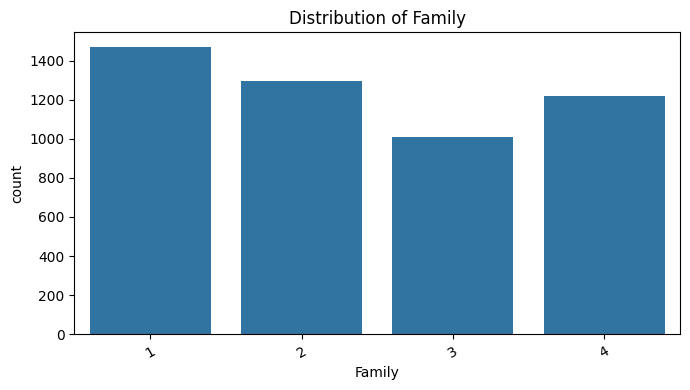

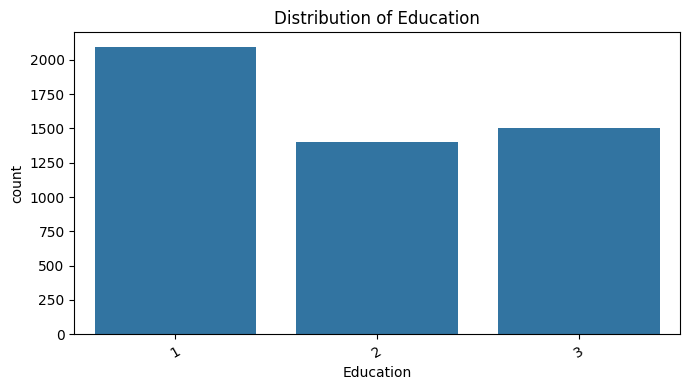

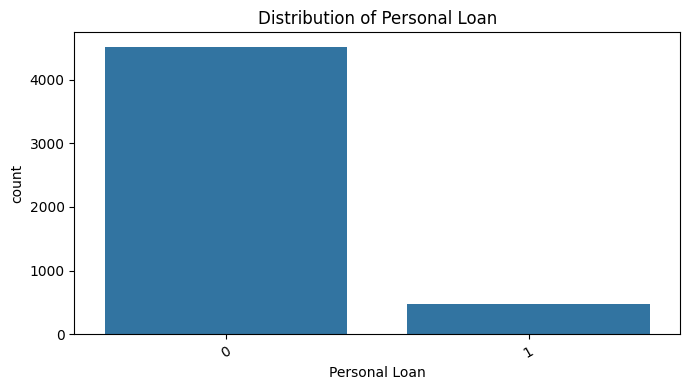

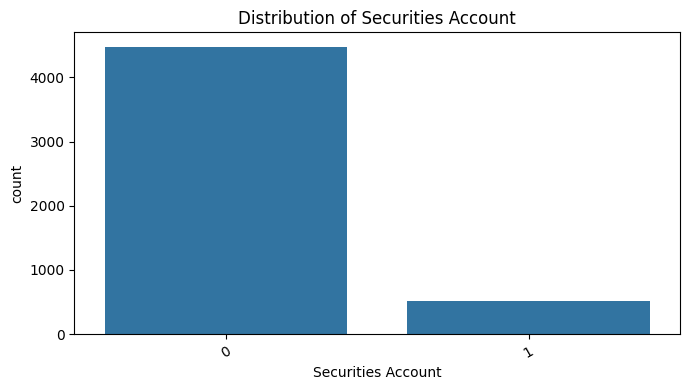

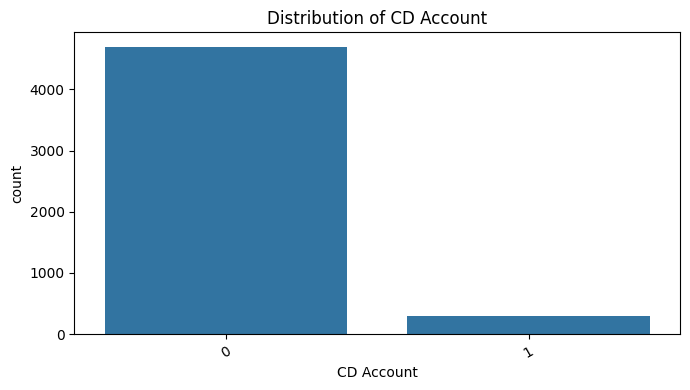

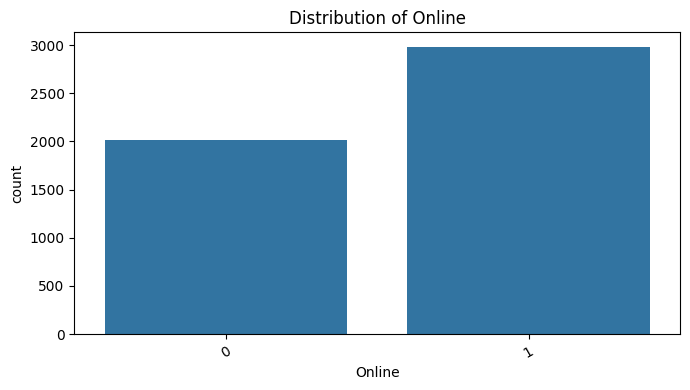

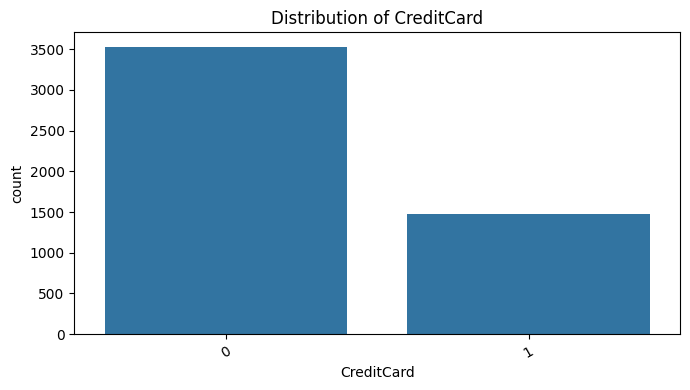

In [ ]:
categorical_cols = [
    col for col in df_clean.columns
    if df_clean[col].nunique(dropna=True) <= 10
]

for col in categorical_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df_clean, x=col)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

Target counts:
Personal Loan
0    4520
1     480
Name: count, dtype: int64

Target percentages:
Personal Loan
0    90.4
1     9.6
Name: proportion, dtype: float64


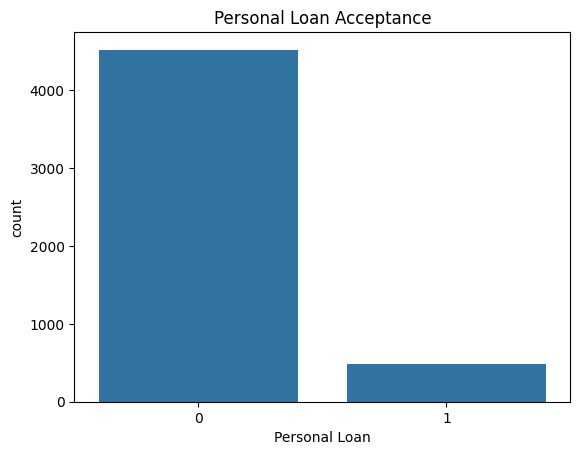

In [ ]:
target = "Personal Loan"

if target in df_clean.columns:
    print("Target counts:")
    print(df_clean[target].value_counts())

    print("\nTarget percentages:")
    print(
        df_clean[target]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    sns.countplot(data=df_clean, x=target)
    plt.title("Personal Loan Acceptance")
    plt.show()
else:
    print("Target column not found. Check your column names.")

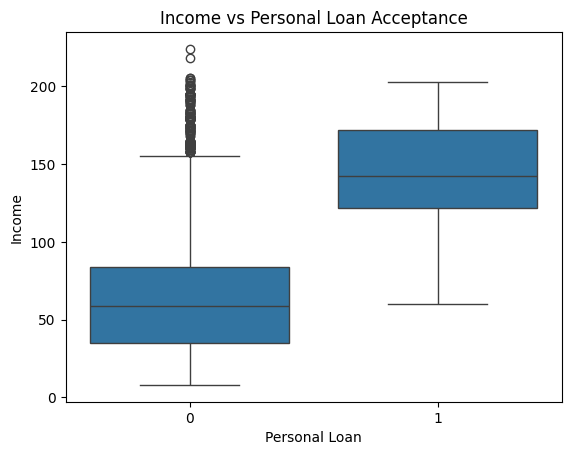

In [ ]:
if {"Income", target}.issubset(df_clean.columns):
    sns.boxplot(data=df_clean, x=target, y="Income")
    plt.title("Income vs Personal Loan Acceptance")
    plt.show()

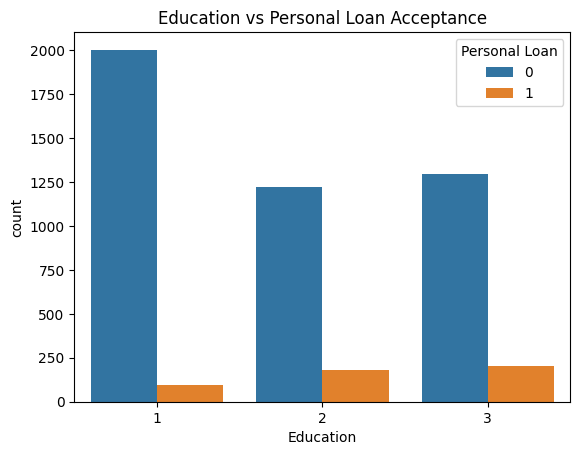

In [ ]:
if {"Education", target}.issubset(df_clean.columns):
    sns.countplot(data=df_clean, x="Education", hue=target)
    plt.title("Education vs Personal Loan Acceptance")
    plt.show()

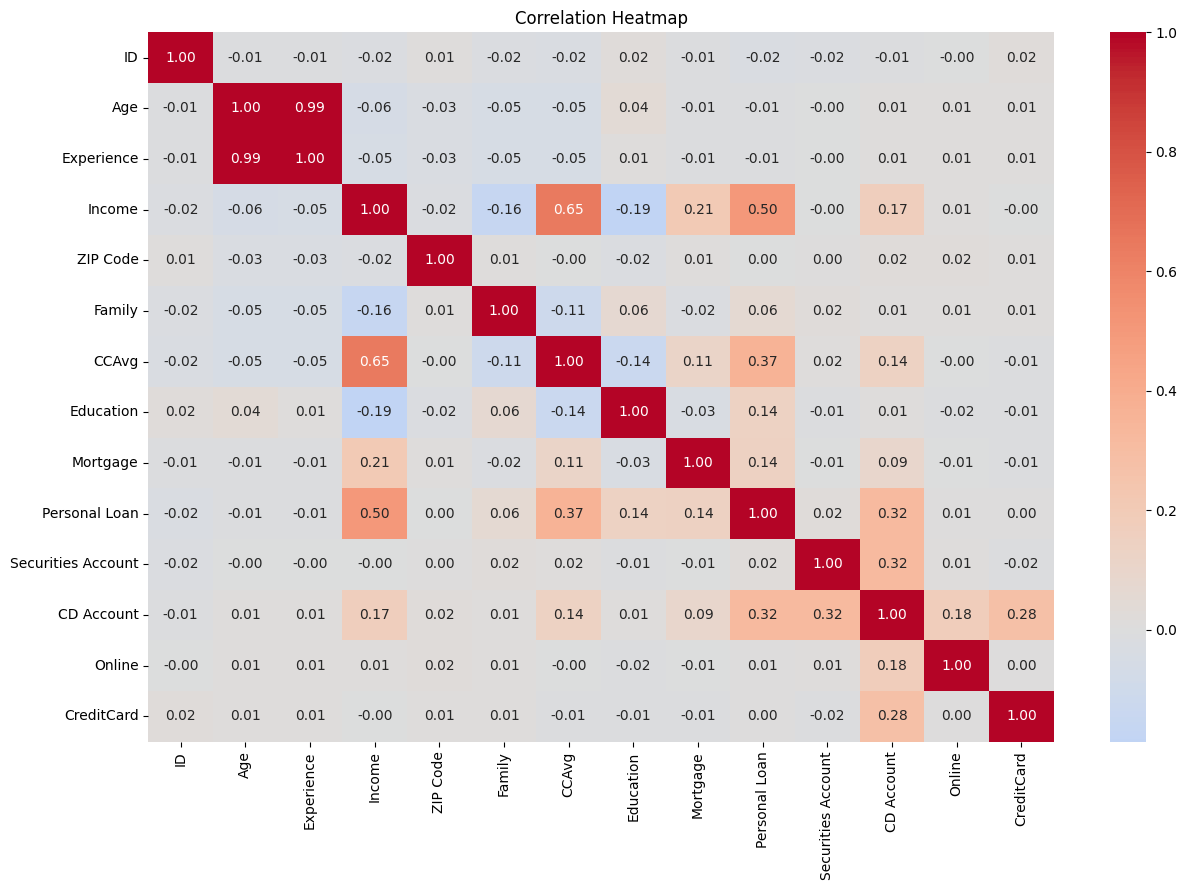

In [ ]:
correlation = df_clean.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(13, 9))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Create cleaned DataFrame if it does not already exist
if "df_clean" not in globals():
    df_clean = df.drop_duplicates().copy()

# Define numerical columns
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical columns:", numeric_cols)

# Calculate outliers using IQR
outlier_results = []

for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count
    })

display(pd.DataFrame(outlier_results))

Numerical columns: ['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


,Feature,Lower Bound,Upper Bound,Outlier Count
0,ID,-2498.5,7499.5,0
1,Age,5.0,85.0,0
2,Experience,-20.0,60.0,0
3,Income,-49.5,186.5,96
4,ZIP Code,87865.5,98653.5,1
5,Family,-2.0,6.0,0
6,CCAvg,-2.0,5.2,324
7,Education,-2.0,6.0,0
8,Mortgage,-151.5,252.5,291
9,Personal Loan,0.0,0.0,480


In [ ]:
target = "Personal Loan"

if target not in df_clean.columns:
    raise ValueError(
        f"Target '{target}' not found. Available columns: {df_clean.columns.tolist()}"
    )

drop_cols = [
    col for col in ["ID", "ZIP Code", "ZIPCode"]
    if col in df_clean.columns
]

model_df = df_clean.drop(columns=drop_cols).copy()

X = model_df.drop(columns=[target])
y = model_df[target]

print("Feature matrix:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", y.unique())

Feature matrix: (5000, 11)
Target shape: (5000,)
Target classes: [0 1]


In [ ]:
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Constant features:", constant_cols)

X = X.drop(columns=constant_cols)

print("Features after removing constants:", X.shape[1])

Constant features: []
Features after removing constants: 11


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

# Split the dataset into training and validation sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing: imputation + scaling
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: imputation + one-hot encoding
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Complete machine learning pipeline
model = Pipeline([
    ("preprocessing", preprocessor),
    ("logistic_regression", LogisticRegression(max_iter=2000))
])

# Train the model
model.fit(X_train, y_train)

print("Train-test split completed!")
print("Feature scaling completed!")
print("Logistic Regression model trained successfully!")

Train-test split completed!
Feature scaling completed!
Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

# Predicted probability of accepting a personal loan
y_prob = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Probability_of_Acceptance": y_prob
})

display(results.head(10))

,Actual,Predicted,Probability_of_Acceptance
0,0,0,0.000154
1,1,1,0.879202
2,0,0,0.000176
3,0,0,0.029719
4,0,0,0.008734
5,0,0,0.006062
6,0,0,0.000985
7,0,0,0.001973
8,0,0,0.089920
9,0,0,0.033907


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [ ]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# ROC-AUC
print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob), 4
))

Accuracy: 0.9550
Accuracy percentage: 95.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       904
           1       0.83      0.67      0.74        96

    accuracy                           0.95      1000
   macro avg       0.90      0.83      0.86      1000
weighted avg       0.95      0.95      0.95      1000

ROC-AUC: 0.9634


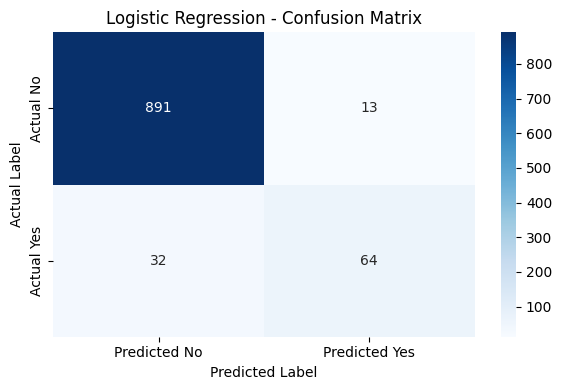

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

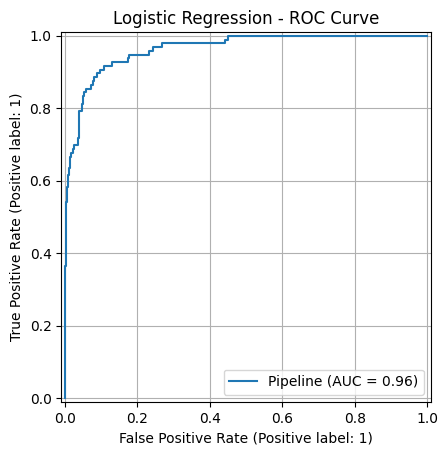

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(model, X_test, y_test)

plt.title("Logistic Regression - ROC Curve")
plt.grid(True)
plt.show()